saved


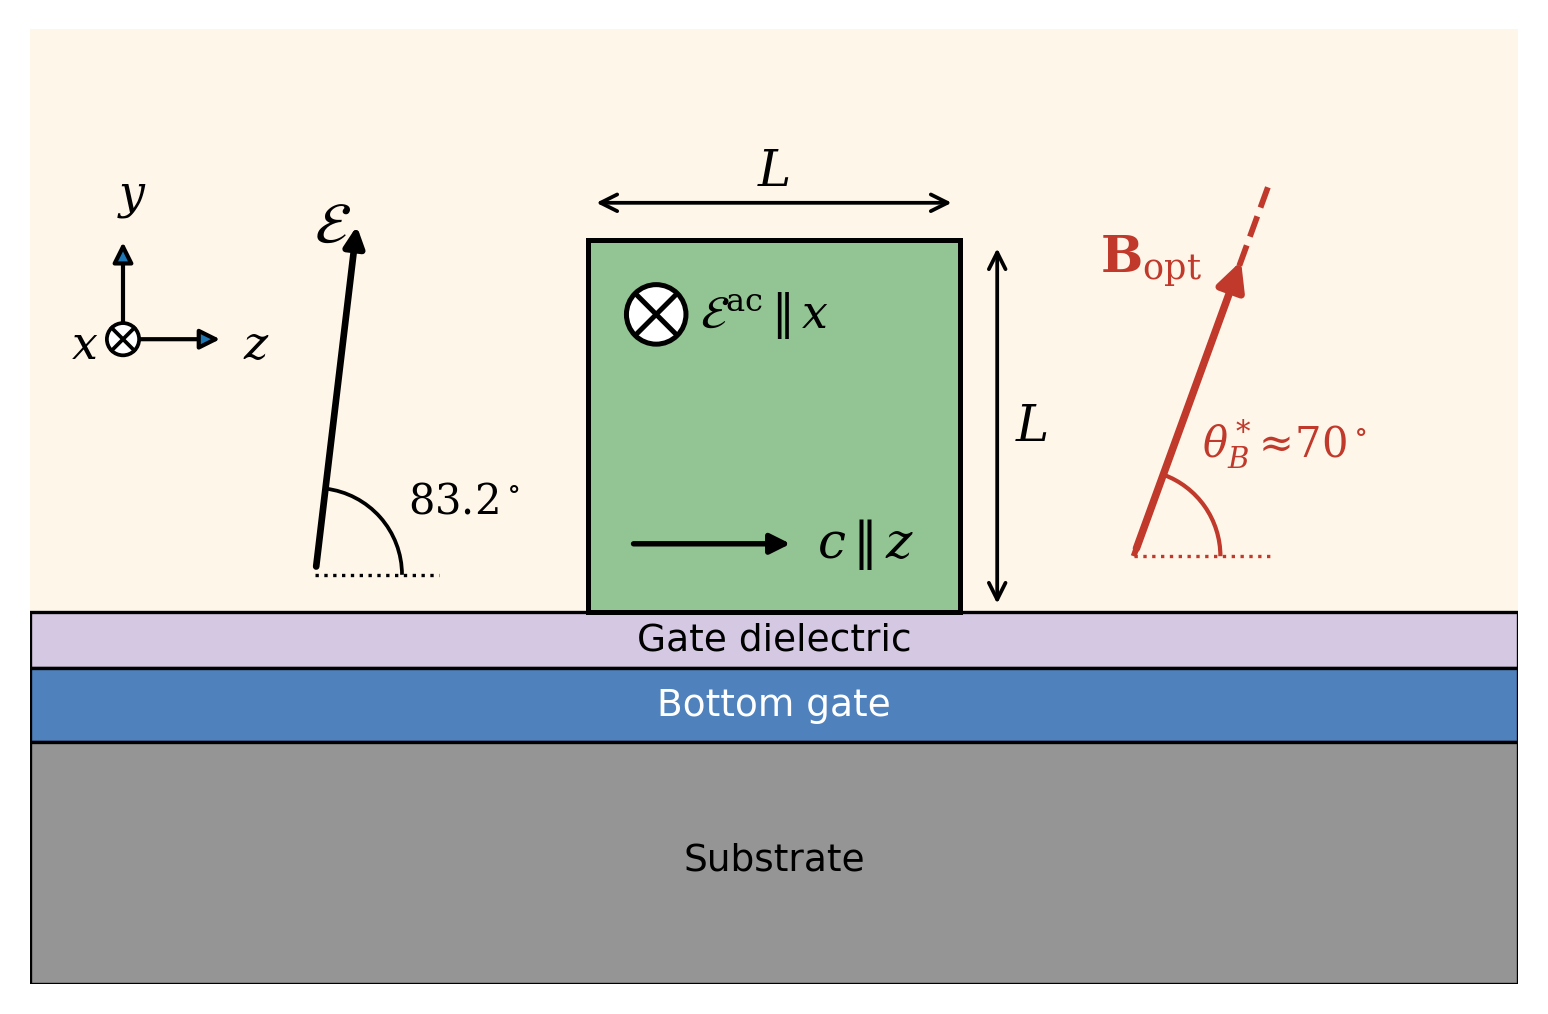

In [5]:
"""Cross-section schematic of the hex-Ge nanowire with tilted DC field,
AC drive along the wire axis (x, into the page) and the optimal-B plane.

Conventions (match slide 5): x = wire axis [10-10], z = c axis, y completes
a right-handed set. In this view z points right, y points up, so x points
INTO the page (x = y × z) -> AC drive drawn as ⊗.

Edit the parameters below and re-run.
"""
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, Arc, FancyArrowPatch

# ---------------- parameters ----------------
THETA_E = 83.2   # DC field angle from the horizontal (z / c axis), degrees
# Polar angle (from z) of the in-(yz)-plane direction u that, together with x,
# spans the plane of maximal Rabi frequency. Read off the f_R(phi, theta_B)
# map at phi = 90 deg (yz plane). ~109 deg assumes theta_B runs 0->180
# top-to-bottom in the map; use ~71 deg if it runs bottom-to-top.
THETA_B = 70.0
OUT = os.path.join("outputs", "schematic_tilted_E")
# --------------------------------------------

os.makedirs(os.path.dirname(OUT), exist_ok=True)
plt.rcParams.update({"mathtext.fontset": "dejavuserif"})
fig, ax = plt.subplots(figsize=(6.4, 4.6), dpi=300)
ax.set_xlim(0, 12); ax.set_ylim(-3.0, 4.7); ax.set_aspect("equal"); ax.axis("off")

# layers
ax.add_patch(Rectangle((0, 0), 12, 4.7, color="#FDF6E9", zorder=0))
ax.add_patch(Rectangle((0, -0.45), 12, 0.45, fc="#D5C8E3", ec="k", lw=0.8))
ax.add_patch(Rectangle((0, -1.05), 12, 0.60, fc="#4F81BD", ec="k", lw=0.8))
ax.add_patch(Rectangle((0, -3.0), 12, 1.95, fc="#959595", ec="k", lw=0.8))
for y, t, c in [(-0.225, "Gate dielectric", "k"), (-0.75, "Bottom gate", "w"),
                (-2.0, "Substrate", "k")]:
    ax.text(6, y, t, ha="center", va="center", fontsize=9, color=c,
            family="sans-serif")

# wire
x0, w = 4.5, 3.0
cx, cy = x0 + w / 2, w / 2
ax.add_patch(Rectangle((x0, 0), w, w, fc="#93C493", ec="k", lw=1.2, zorder=2))

# L dimensions
def dim(p, q, label, off):
    ax.annotate("", p, q, arrowprops=dict(arrowstyle="<->", lw=0.9))
    ax.text((p[0] + q[0]) / 2 + off[0], (p[1] + q[1]) / 2 + off[1], label,
            ha="center", va="center", fontsize=12, style="italic", family="serif")
dim((x0, w + 0.3), (x0 + w, w + 0.3), "$L$", (0, 0.25))
dim((x0 + w + 0.3, 0), (x0 + w + 0.3, w), "$L$", (0.28, 0))

# c axis inside wire (z)
ax.annotate("", (x0 + 1.7, 0.55), (x0 + 0.3, 0.55),
            arrowprops=dict(arrowstyle="-|>", lw=1.3, color="k"), zorder=4)
ax.text(x0 + 1.85, 0.55, r"$c\,\|\,z$", fontsize=12, va="center", zorder=4)

# AC drive along x (into the page): circled cross
ox, oy, r = x0 + 0.55, w - 0.6, 0.24
ax.add_patch(Circle((ox, oy), r, fc="white", ec="k", lw=1.2, zorder=5))
d = r * 0.68
ax.plot([ox - d, ox + d], [oy - d, oy + d], "k", lw=1.2, zorder=6)
ax.plot([ox - d, ox + d], [oy + d, oy - d], "k", lw=1.2, zorder=6)
ax.text(ox + 0.35, oy, r"$\mathcal{E}^{\rm ac}\,\|\,x$", fontsize=11,
        va="center", zorder=6)

# optimal-B plane: contains x (out of view) and u (in yz plane) -> a line here
tb = np.deg2rad(THETA_B)
u = np.array([np.cos(tb), np.sin(tb)])          # (z, y) components -> (right, up)
bx, by = 8.9, 0.45                              # origin of the B construction
ext = 3.2
p1, p2 = np.array([bx, by]) - 0.0 * u, np.array([bx, by]) + ext * u
ax.plot([p1[0], p2[0]], [p1[1], p2[1]], ls="--", color="#C0392B", lw=1.4, zorder=3)
arr = FancyArrowPatch((bx, by), (bx + 2.6 * u[0], by + 2.6 * u[1]),
                      arrowstyle="-|>", mutation_scale=14, lw=1.8,
                      color="#C0392B", zorder=7)
ax.add_patch(arr)
ax.text(bx + 2.6 * u[0] - 0.75, by + 2.6 * u[1] - 0.15,
        r"$\mathbf{B}_{\rm opt}$", color="#C0392B", fontsize=12, ha="center")
# angle arc from c (horizontal) to u
ax.plot([bx, bx + 1.1], [by, by], color="#C0392B", lw=0.8, ls=":", zorder=3)
ax.add_patch(Arc((bx, by), 1.4, 1.4, theta1=0, theta2=THETA_B,
                 color="#C0392B", lw=1.0, zorder=7))
ax.text(bx + 0.55, by + 0.8, rf"$\theta_B^*\!\approx\!{THETA_B:.0f}^\circ$",
        color="#C0392B", fontsize=10, zorder=7)

# DC field, tilted THETA_E from horizontal
te = np.deg2rad(THETA_E)
e0 = np.array([2.3, 0.3]); el = 2.9
e1 = e0 + el * np.array([np.cos(te), np.sin(te)])
ax.annotate("", e1, e0, arrowprops=dict(arrowstyle="-|>", lw=1.6, color="k"))
ax.text(e1[0] - 0.35, e1[1] - 0.2, r"$\mathcal{E}$", fontsize=14)
ax.plot([e0[0], e0[0] + 1.0], [e0[1], e0[1]], "k:", lw=0.8)
ax.add_patch(Arc(tuple(e0), 1.4, 1.4, theta1=0, theta2=THETA_E, lw=0.9))
ax.text(e0[0] + 0.75, e0[1] + 0.5, rf"${THETA_E}^\circ$", fontsize=10)

# axis triad (y up, z right, x into page)
t0 = np.array([0.75, 2.2])
for v, lab, off in [((0.85, 0), "$z$", (0.12, -0.05)), ((0, 0.85), "$y$", (-0.05, 0.12))]:
    ax.annotate("", tuple(t0 + v), tuple(t0),
                arrowprops=dict(arrowstyle="-|>", lw=1.0))
    ax.text(*(t0 + v + off), lab, fontsize=11, va="bottom" if v[1] else "center")
ax.add_patch(Circle(tuple(t0), 0.13, fc="white", ec="k", lw=0.9, zorder=5))
dd = 0.09
ax.plot([t0[0]-dd, t0[0]+dd], [t0[1]-dd, t0[1]+dd], "k", lw=0.9, zorder=6)
ax.plot([t0[0]-dd, t0[0]+dd], [t0[1]+dd, t0[1]-dd], "k", lw=0.9, zorder=6)
ax.text(t0[0] - 0.2, t0[1] - 0.05, "$x$", fontsize=11, ha="right", va="center")


for ext_ in ("png", "svg", "pdf"):
    fig.savefig(f"{OUT}.{ext_}", bbox_inches="tight", pad_inches=0.02)
print("saved")
